Dataset 'student_data.csv' not found. Downloading the UCI Student Performance Dataset...
Download complete and dataset prepared!
Dataset Shape :  (395, 33)
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3     

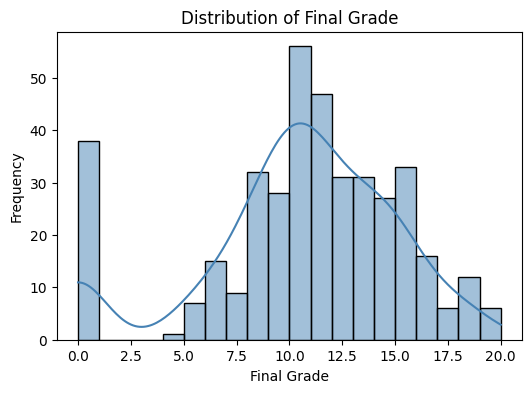

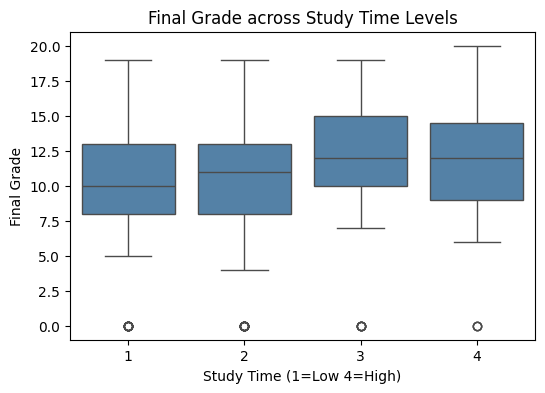

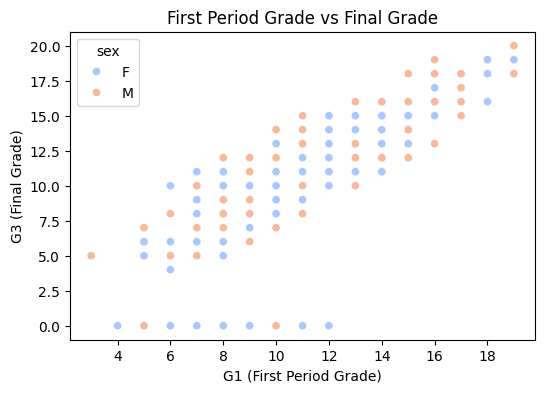

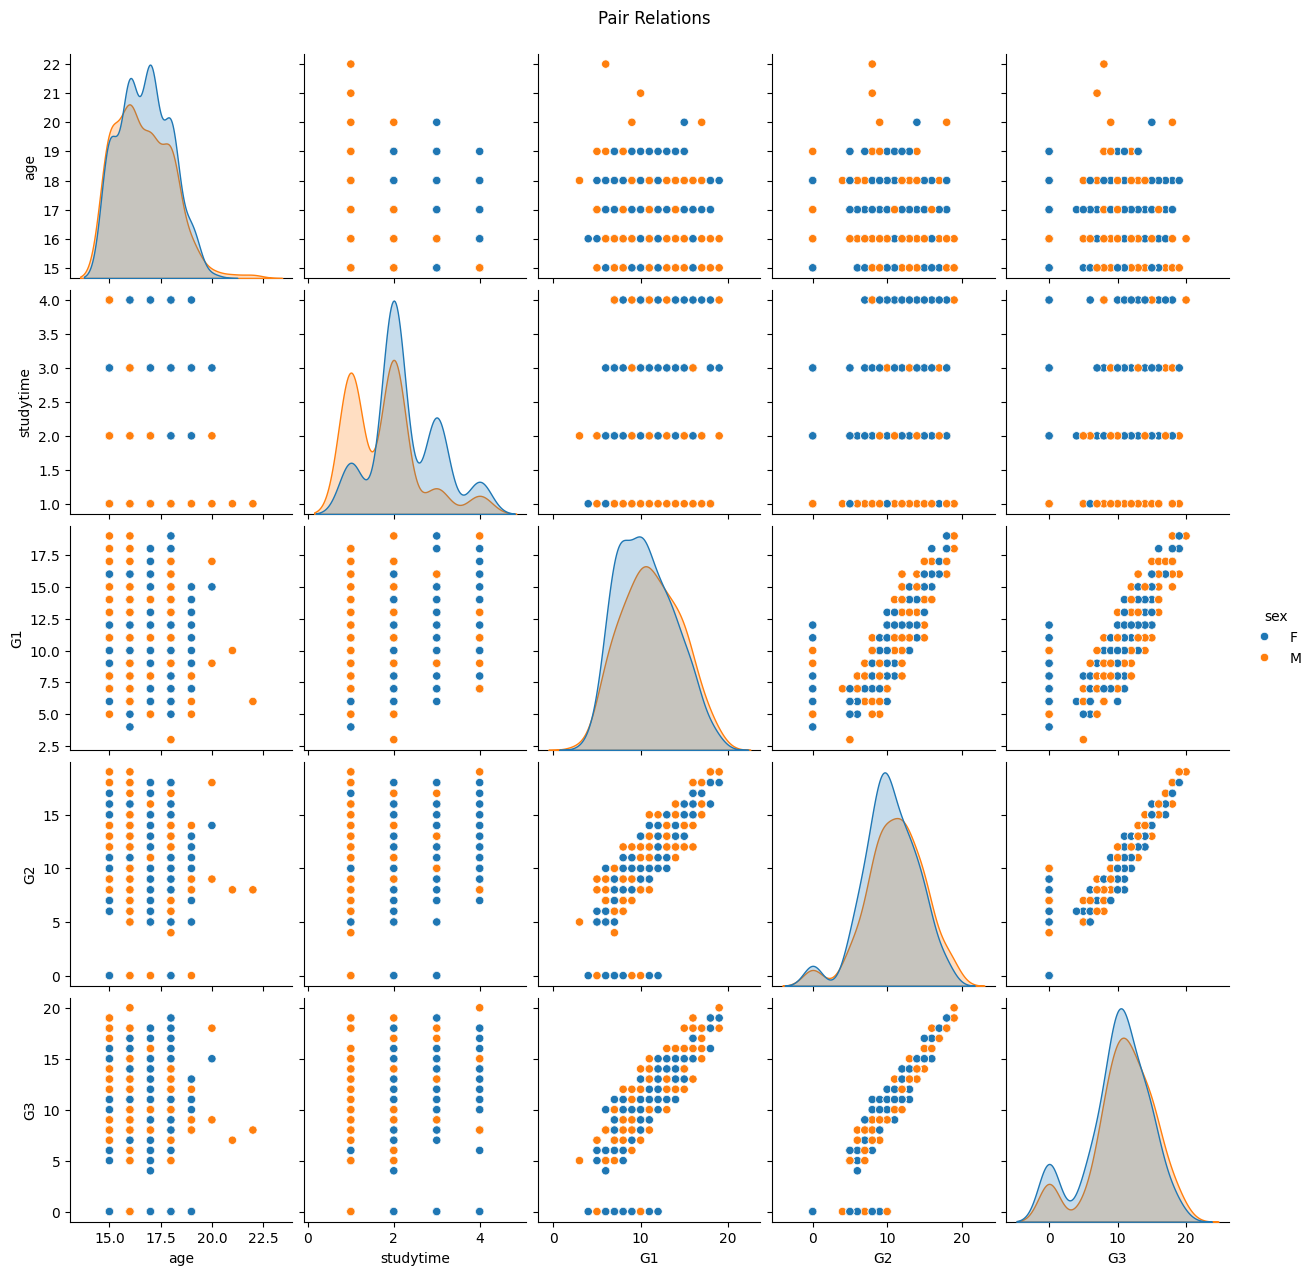

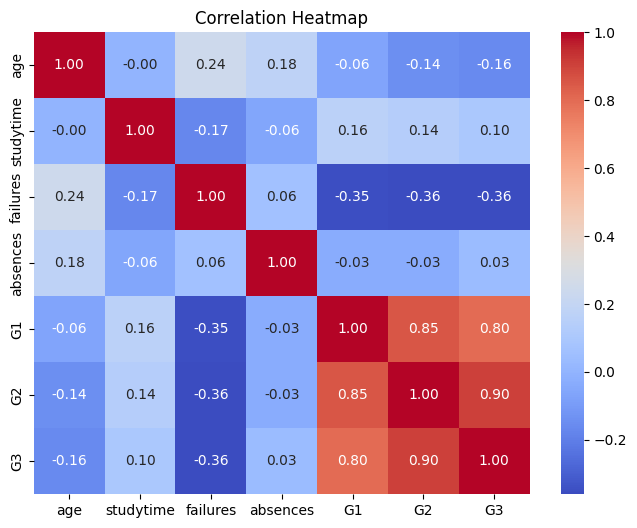

In [ ]:
from pathlib import Path
import urllib.request
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

csv_path = Path("student_data.csv")
if not csv_path.exists():
    print("Dataset 'student_data.csv' not found. Downloading the UCI Student Performance Dataset...")
    url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
    zip_path = Path("student_performance.zip")
    urllib.request.urlretrieve(url, zip_path)

    # Extract the outer zip file
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(".")

    # Extract the inner 'student.zip' file
    inner_zip = Path("student.zip")
    if inner_zip.exists():
        with zipfile.ZipFile(inner_zip, 'r') as zip_ref:
            zip_ref.extractall(".")

    # Now 'student-mat.csv' should exist
    if Path("student-mat.csv").exists():
        Path("student-mat.csv").rename(csv_path)
        print("Download complete and dataset prepared!")
    else:
        raise FileNotFoundError("Could not find 'student-mat.csv' inside the extracted files.")

df = pd.read_csv(csv_path, sep=";")
print("Dataset Shape : ",df.shape)
print(df.head())
print("Dataset Information : ")
df.info()
print("Dataset Description : \n",df.describe())
plt.figure(figsize=(6,4))
sns.histplot(df["G3"], bins=20,kde=True,color="steelblue")
plt.title("Distribution of Final Grade")
plt.xlabel("Final Grade")
plt.ylabel("Frequency")
plt.show()
plt.figure(figsize=(6,4))
sns.boxplot(x="studytime",y="G3",data=df,color="steelblue")
plt.title("Final Grade across Study Time Levels")
plt.xlabel("Study Time (1=Low 4=High)")
plt.ylabel("Final Grade")
plt.show()
plt.figure(figsize=(6,4))
sns.scatterplot(x="G1",y="G3",hue="sex",data=df,palette="coolwarm")
plt.title("First Period Grade vs Final Grade")
plt.xlabel("G1 (First Period Grade)")
plt.ylabel("G3 (Final Grade)")
plt.show()
sns.pairplot(df[["age","studytime","G1","G2","G3","sex"]],hue="sex")
plt.suptitle("Pair Relations",y=1.02)
plt.show()
numeric_cols = ["age","studytime","failures","absences","G1","G2","G3"]
plt.figure(figsize=(8,6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()